In [1]:
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt

In [2]:
RESULTS_DIR = 'results'
MODELS_DIR = 'models'

LOCALIZATION_VALIDATION_CSV_DIR = f'{RESULTS_DIR}/localization_validation_konkle.csv'
SUBJECTSUBJECT_PEARSONR_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_pearsonr_nsd515.csv'
MODELSUBJECT_PEARSONR_CSV_PATH = f'{RESULTS_DIR}/modelsubject_pearsonr_nsd515.csv'
NOLAYEROPT_MODELSUBJECT_PEARSONR_CSV_PATH = f'{RESULTS_DIR}/nolayeropt_modelsubject_pearsonr_nsd515.csv'

# Localization Validation

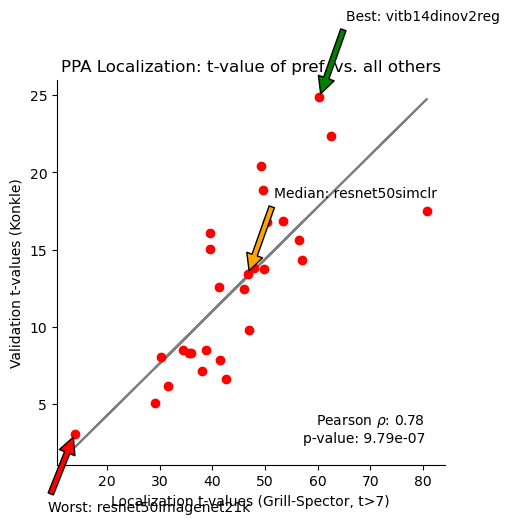

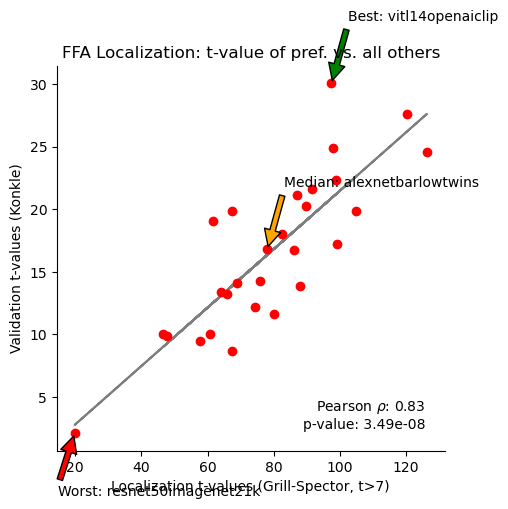

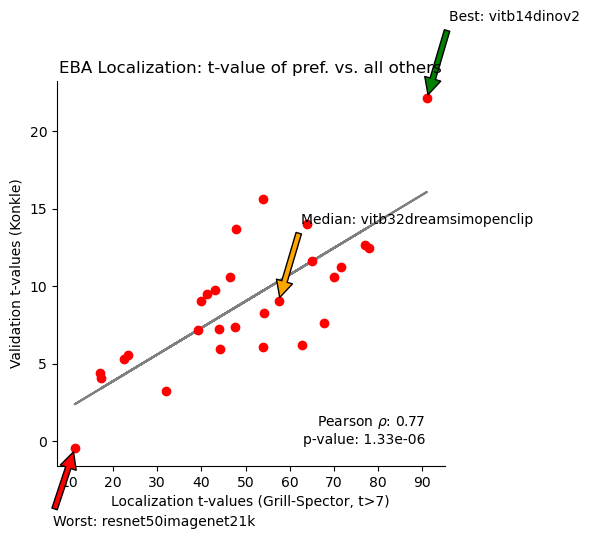

In [19]:
localization_validation_df = pd.read_csv(LOCALIZATION_VALIDATION_CSV_DIR)

frois = localization_validation_df['model_froi'].unique()

annotate_models = True

for froi in frois:
    froi_df = localization_validation_df[localization_validation_df['model_froi'] == froi]
    localization_tvalues = froi_df['localization_tvalue'].values
    validation_tvalues = froi_df['validation_tvalue'].values

    fig = plt.figure(figsize=(5, 5), dpi=100)
    m, b = np.polyfit(localization_tvalues, validation_tvalues, 1)
    plt.plot(localization_tvalues, m*localization_tvalues + b, color='k', alpha=0.5)
    plt.scatter(localization_tvalues, validation_tvalues, color='red', alpha=1, zorder=2)

    # Calculate Pearson correlation
    r, p_value = scipy.stats.pearsonr(localization_tvalues, validation_tvalues)
    plt.text(0.95, 0.05, rf"Pearson $\rho$: {r:.2f}" + '\n' + f"p-value: {p_value:.2e}", 
             horizontalalignment='right', verticalalignment='bottom', 
             transform=plt.gca().transAxes)

    if annotate_models:
        best_model_idx = np.argmax(validation_tvalues)
        worst_model_idx = np.argmin(validation_tvalues)
        median_model_idx = np.argsort(validation_tvalues)[len(validation_tvalues) // 2]
        best_model_name = froi_df.iloc[best_model_idx]['model_name']
        worst_model_name = froi_df.iloc[worst_model_idx]['model_name']
        median_model_name = froi_df.iloc[median_model_idx]['model_name']

        plt.annotate(f'Best: {best_model_name}', xy=(localization_tvalues[best_model_idx], validation_tvalues[best_model_idx]), 
                     xytext=(localization_tvalues[best_model_idx]+5, validation_tvalues[best_model_idx]+5),
                     arrowprops=dict(facecolor='green', shrink=0.05))
        plt.annotate(f'Worst: {worst_model_name}', xy=(localization_tvalues[worst_model_idx], validation_tvalues[worst_model_idx]), 
                     xytext=(localization_tvalues[worst_model_idx]-5, validation_tvalues[worst_model_idx]-5),
                     arrowprops=dict(facecolor='red', shrink=0.05))
        plt.annotate(f'Median: {median_model_name}', xy=(localization_tvalues[median_model_idx], validation_tvalues[median_model_idx]), 
                     xytext=(localization_tvalues[median_model_idx]+5, validation_tvalues[median_model_idx]+5),
                     arrowprops=dict(facecolor='orange', shrink=0.05))

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.xlabel('Localization t-values (Grill-Spector, t>7)')
    plt.ylabel('Validation t-values (Konkle)')
    plt.title(f'{froi} Localization: t-value of pref. vs. all others')
    plt.show()

# Model & Human Univariate Comparison

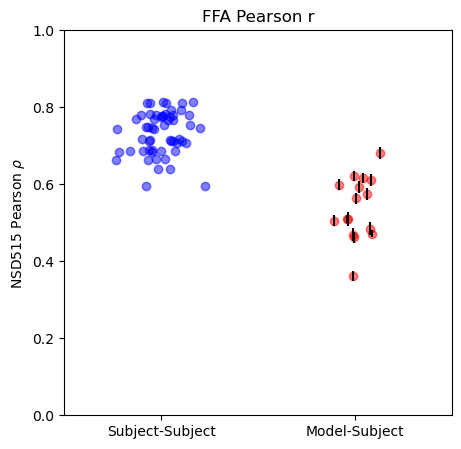

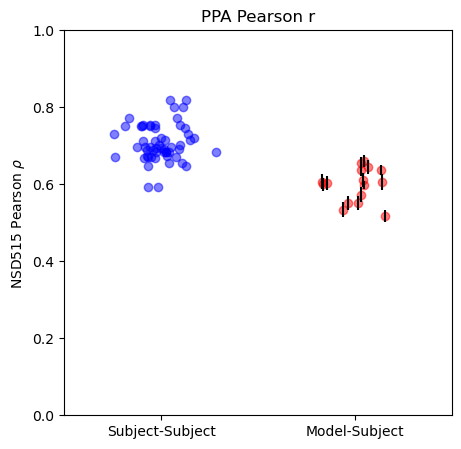

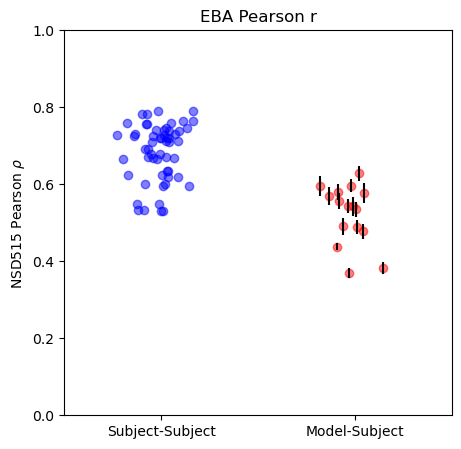

In [ ]:
subjectsubject_univariate_csv = pd.read_csv(SUBJECTSUBJECT_PEARSONR_CSV_PATH)
modelsubject_univariate_csv = pd.read_csv(MODELSUBJECT_PEARSONR_CSV_PATH)

frois = subjectsubject_univariate_csv['fmri_froi'].unique()
subjects = subjectsubject_univariate_csv['subject1'].unique()
models = modelsubject_univariate_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
annotate_models = False

for froi in ['FFA', 'PPA', 'EBA']:
    hh_means = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_univariate_csv[
            (subjectsubject_univariate_csv['fmri_froi'] == froi) &
            (subjectsubject_univariate_csv['subject1'] == subject)
        ]
        hh_means.append(subjectsubject_froi['pearsonr'])
    hh_means = np.array(hh_means).flatten()

    mh_means, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_univariate_csv[
            (modelsubject_univariate_csv['fmri_froi'] == froi) &
            (modelsubject_univariate_csv['model_froi'] == froi) &
            (modelsubject_univariate_csv['model_name'] == model)
        ]
        mh_means.append(modelsubject_froi['pearsonr'].mean())
        mh_sems.append(modelsubject_froi['pearsonr'].sem())
    mh_means = np.array(mh_means)
    mh_sems = np.array(mh_sems)

    best_model_idx = np.argmax(mh_means)
    worst_model_idx = np.argmin(mh_means)
    median_model_idx = np.argsort(mh_means)[len(mh_means) // 2]
    best_model_name = models[best_model_idx]
    worst_model_name = models[worst_model_idx]
    median_model_name = models[median_model_idx]

    resnet50imagenet1kv2_idx = np.where(models == 'resnet50imagenet1kv2')[0][0]
    resnet50imagenet1kv2_name = models[resnet50imagenet1kv2_idx]

    fig = plt.figure(figsize=(5, 5), dpi=100)
    x_subjectsubject = np.zeros(len(hh_means)) + np.random.normal(0, 0.1, len(hh_means))
    x_modelsubject = np.ones(len(mh_means)) + np.random.normal(0, 0.1, len(mh_means))
    plt.errorbar(
        x_modelsubject, mh_means, yerr=mh_sems, fmt='.', ecolor='k', \
        markersize=0, capsize=0, label='Model-Subject'
    )
    plt.scatter(x_subjectsubject, hh_means, color='blue', alpha=0.5, label='Subject-Subject')
    plt.scatter(x_modelsubject, mh_means, color='red', alpha=0.5, label='Model-Subject')
    if annotate_models:
        plt.annotate(f'Best: {best_model_name}', xy=(1.25, mh_means[best_model_idx]), xytext=(1.3, mh_means[best_model_idx]+0.05),
                    arrowprops=dict(facecolor='green', shrink=0.005))
        plt.annotate(f'Worst: {worst_model_name}', xy=(1.25, mh_means[worst_model_idx]), xytext=(1.3, mh_means[worst_model_idx]-0.05),
                    arrowprops=dict(facecolor='red', shrink=0.005))
        plt.annotate(f'Median: {median_model_name}', xy=(1.25, mh_means[median_model_idx]), xytext=(1.3, mh_means[median_model_idx]),
                    arrowprops=dict(facecolor='orange', shrink=0.005))
        plt.annotate(f'ResNet50: {resnet50imagenet1kv2_name}', xy=(1.25, mh_means[resnet50imagenet1kv2_idx]), xytext=(1.3, mh_means[resnet50imagenet1kv2_idx]),
                    arrowprops=dict(facecolor='blue', shrink=0.005))
    plt.xticks([0, 1], ['Subject-Subject', 'Model-Subject'])
    plt.ylabel(r'NSD515 Pearson $\rho$')
    plt.title(f'{froi} Pearson r')
    plt.xlim(-0.5, 1.5)
    plt.ylim(0, 1)
    # plt.legend()
    plt.show()
    plt.close()

# Model & Human Univariate Comparison (No Layer Optimization)

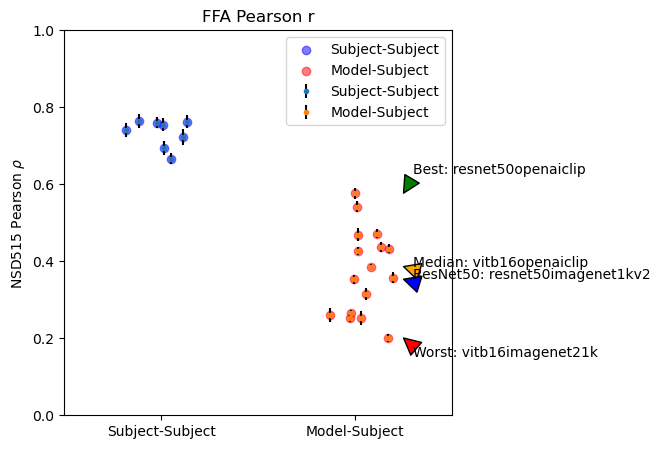

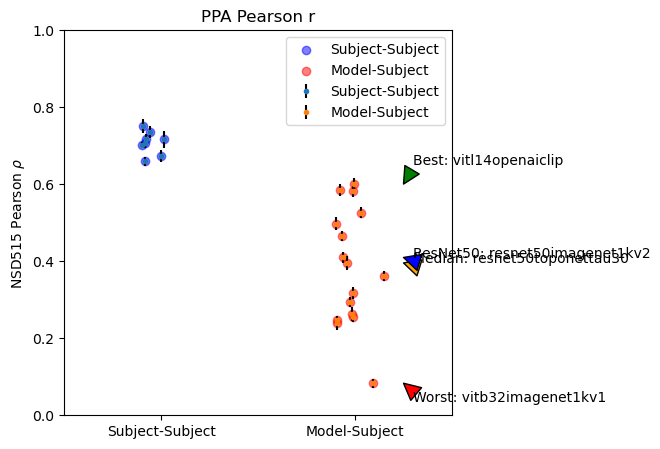

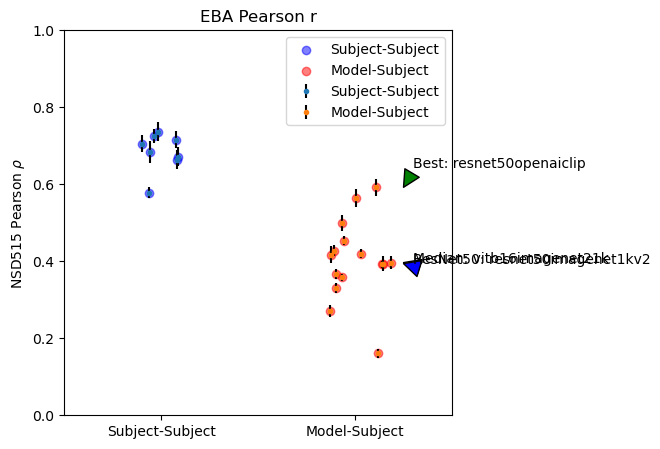

In [34]:
subjectsubject_univariate_csv = pd.read_csv(SUBJECTSUBJECT_PEARSONR_CSV_PATH)
modelsubject_univariate_csv = pd.read_csv(NOLAYEROPT_MODELSUBJECT_PEARSONR_CSV_PATH)

frois = subjectsubject_univariate_csv['fmri_froi'].unique()
subjects = subjectsubject_univariate_csv['subject1'].unique()
models = modelsubject_univariate_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
annotate_models = True

for froi in ['FFA', 'PPA', 'EBA']:
    hh_means, hh_sems = [], []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_univariate_csv[
            (subjectsubject_univariate_csv['fmri_froi'] == froi) &
            (subjectsubject_univariate_csv['subject1'] == subject)
        ]
        hh_means.append(subjectsubject_froi['pearsonr'].mean())
        hh_sems.append(subjectsubject_froi['pearsonr'].sem())
    hh_means = np.array(hh_means)
    hh_sems = np.array(hh_sems)

    mh_means, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_univariate_csv[
            (modelsubject_univariate_csv['fmri_froi'] == froi) &
            (modelsubject_univariate_csv['model_froi'] == froi) &
            (modelsubject_univariate_csv['model_name'] == model)
        ]
        mh_means.append(modelsubject_froi['pearsonr'].mean())
        mh_sems.append(modelsubject_froi['pearsonr'].sem())
    mh_means = np.array(mh_means)
    mh_sems = np.array(mh_sems)

    best_model_idx = np.argmax(mh_means)
    worst_model_idx = np.argmin(mh_means)
    median_model_idx = np.argsort(mh_means)[len(mh_means) // 2]
    best_model_name = models[best_model_idx]
    worst_model_name = models[worst_model_idx]
    median_model_name = models[median_model_idx]

    resnet50imagenet1kv2_idx = np.where(models == 'resnet50imagenet1kv2')[0][0]
    resnet50imagenet1kv2_name = models[resnet50imagenet1kv2_idx]

    fig = plt.figure(figsize=(5, 5), dpi=100)
    x_subjectsubject = np.zeros(len(hh_means)) + np.random.normal(0, 0.1, len(hh_means))
    x_modelsubject = np.ones(len(mh_means)) + np.random.normal(0, 0.1, len(mh_means))
    plt.scatter(x_subjectsubject, hh_means, color='blue', alpha=0.5, label='Subject-Subject')
    plt.scatter(x_modelsubject, mh_means, color='red', alpha=0.5, label='Model-Subject')
    plt.errorbar(
        x_subjectsubject, hh_means, yerr=hh_sems, fmt='.', ecolor='k', \
        capsize=0, label='Subject-Subject'
    )
    plt.errorbar(
        x_modelsubject, mh_means, yerr=mh_sems, fmt='.', ecolor='k', \
        capsize=0, label='Model-Subject'
    )
    if annotate_models:
        plt.annotate(f'Best: {best_model_name}', xy=(1.25, mh_means[best_model_idx]), xytext=(1.3, mh_means[best_model_idx]+0.05),
                    arrowprops=dict(facecolor='green', shrink=0.005))
        plt.annotate(f'Worst: {worst_model_name}', xy=(1.25, mh_means[worst_model_idx]), xytext=(1.3, mh_means[worst_model_idx]-0.05),
                    arrowprops=dict(facecolor='red', shrink=0.005))
        plt.annotate(f'Median: {median_model_name}', xy=(1.25, mh_means[median_model_idx]), xytext=(1.3, mh_means[median_model_idx]),
                    arrowprops=dict(facecolor='orange', shrink=0.005))
        plt.annotate(f'ResNet50: {resnet50imagenet1kv2_name}', xy=(1.25, mh_means[resnet50imagenet1kv2_idx]), xytext=(1.3, mh_means[resnet50imagenet1kv2_idx]),
                    arrowprops=dict(facecolor='blue', shrink=0.005))
    plt.xticks([0, 1], ['Subject-Subject', 'Model-Subject'])
    plt.ylabel(r'NSD515 Pearson $\rho$')
    plt.title(f'{froi} Pearson r')
    plt.xlim(-0.5, 1.5)
    plt.ylim(0, 1)
    plt.legend()
    plt.show()
    plt.close()